# El tsunami de Tumaco de 1979: qué dicen las observaciones

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/teoria-riesgos/blob/main/book/03_amenazas/318_tsunami_tumaco_1979.ipynb)

Este cuaderno revisa las **observaciones históricas del tsunami del 12 de diciembre de 1979** (sismo de Mw 8,2 en la zona de subducción colombo-ecuatoriana) que reúne el cuaderno piloto de la UNGRD «Simulación del Tsunami de Tumaco de 1979» ([cuadernos-reproducibles-crc003](https://scr-ungrd.github.io/cuadernos-reproducibles-crc003/), licencia MIT, sin validar). Ese cuaderno simula la propagación con aguas someras linealizadas; aquí no se repite la simulación, sino que se usa su tabla de observaciones para dos preguntas que sirven al análisis de una ciudad: **¿cómo cambia el run-up con la distancia a la fuente?** y **¿son coherentes los tiempos de arribo con la física de la onda larga?**

Epicentro usado por el cuaderno de la UNGRD: 1,598° N, 79,359° O. Las observaciones provienen, según la tabla, de Herd et al. (1981) y de la base de datos de tsunamis de la NOAA (NGDC). **Los valores no se han contrastado con las fuentes primarias.**

In [1]:
CSV = r'''estacion,lat,lon,runup_m,tiempo_arr_min,fuente
Tumaco (muelle),1.82,-78.76,5.0,15,Herd et al. 1981
Tumaco (playa),1.80,-78.80,4.5,15,Herd et al. 1981
Bocagrande,1.73,-78.94,3.0,18,Herd et al. 1981
San Juan,1.23,-77.97,2.5,25,NOAA NGDC
El Charco,2.47,-78.11,1.5,30,NOAA NGDC
Esmeraldas (Ecuador),0.97,-79.65,4.0,12,Herd et al. 1981
Buenaventura,3.88,-77.02,0.8,45,NOAA NGDC
Salinas (Ecuador),-2.20,-80.97,1.2,35,NOAA NGDC'''

In [2]:
from io import StringIO
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS = "#0154a5", "#c0392b", "#6b7785"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
EPI = (1.598, -79.359)
obs = pd.read_csv(StringIO(CSV)).rename(columns={"estacion": "Estación", "runup_m": "run-up (m)", "tiempo_arr_min": "arribo (min)"})

def distancia_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

obs["distancia (km)"] = distancia_km(EPI[0], EPI[1], obs["lat"], obs["lon"]).round(0)
obs[["Estación", "distancia (km)", "run-up (m)", "arribo (min)", "fuente"]]

,Estación,distancia (km),run-up (m),arribo (min),fuente
0,Tumaco (muelle),71.0,5.0,15,Herd et al. 1981
1,Tumaco (playa),66.0,4.5,15,Herd et al. 1981
2,Bocagrande,49.0,3.0,18,Herd et al. 1981
3,San Juan,160.0,2.5,25,NOAA NGDC
4,El Charco,169.0,1.5,30,NOAA NGDC
5,Esmeraldas (Ecuador),77.0,4.0,12,Herd et al. 1981
6,Buenaventura,363.0,0.8,45,NOAA NGDC
7,Salinas (Ecuador),459.0,1.2,35,NOAA NGDC


## 1. Run-up y distancia a la fuente

El run-up es la altura máxima que alcanza el agua en tierra. Con solo ocho estaciones no se ajusta ninguna ley, pero la figura muestra el patrón: los valores mayores están cerca de la fuente (Tumaco, Esmeraldas) y bajan hacia el norte (Buenaventura) y el sur (Salinas).

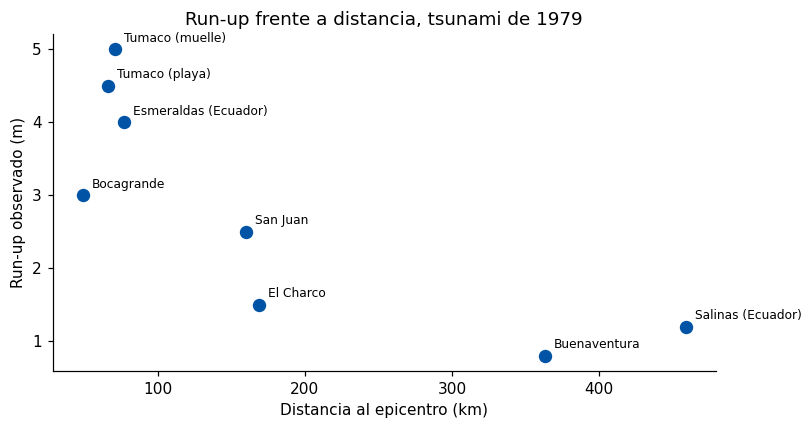

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(obs["distancia (km)"], obs["run-up (m)"], s=60, c=AZUL)
for _, r in obs.iterrows():
    ax.annotate(r["Estación"], (r["distancia (km)"], r["run-up (m)"]), textcoords="offset points", xytext=(6, 5), fontsize=8)
ax.set(xlabel="Distancia al epicentro (km)", ylabel="Run-up observado (m)", title="Run-up frente a distancia, tsunami de 1979")
plt.tight_layout(); plt.show()

## 2. Tiempos de arribo y velocidad de la onda larga

Un tsunami viaja como onda larga con celeridad $c = \sqrt{g\,H}$, donde $H$ es la profundidad. Si el tiempo de arribo en una estación es $t$ y la distancia es $d$, la velocidad media es $d/t$ y la profundidad media equivalente es $H = (d/t)^2 / g$. En el océano abierto frente a Colombia las profundidades llegan a 3 000–4 000 m ($c \approx 170$–$200$ m/s); en la plataforma son de decenas a cientos de metros.

,Estación,distancia (km),arribo (min),velocidad media (m/s),profundidad equivalente (m)
0,Tumaco (muelle),71.0,15,79.0,640.0
1,Tumaco (playa),66.0,15,73.0,540.0
2,Bocagrande,49.0,18,45.0,210.0
3,San Juan,160.0,25,107.0,1170.0
4,El Charco,169.0,30,94.0,900.0
5,Esmeraldas (Ecuador),77.0,12,107.0,1170.0
6,Buenaventura,363.0,45,134.0,1830.0
7,Salinas (Ecuador),459.0,35,219.0,4890.0


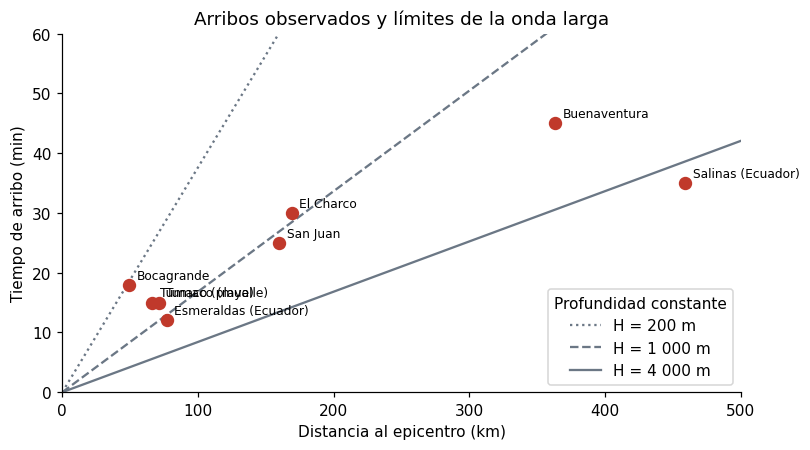

In [4]:
g = 9.81
obs["velocidad media (m/s)"] = (obs["distancia (km)"] * 1000 / (obs["arribo (min)"] * 60)).round(0)
obs["profundidad equivalente (m)"] = ((obs["velocidad media (m/s)"]) ** 2 / g).round(-1)
display(obs[["Estación", "distancia (km)", "arribo (min)", "velocidad media (m/s)", "profundidad equivalente (m)"]])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
d = np.linspace(0, 500, 100)
for H, estilo in [(200, ":"), (1000, "--"), (4000, "-")]:
    ax.plot(d, d * 1000 / np.sqrt(g * H) / 60, estilo, c=GRIS, label=f"H = {H:,} m".replace(",", " "))
ax.scatter(obs["distancia (km)"], obs["arribo (min)"], s=60, c=ROJO, zorder=3)
for _, r in obs.iterrows():
    ax.annotate(r["Estación"], (r["distancia (km)"], r["arribo (min)"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.set(xlabel="Distancia al epicentro (km)", ylabel="Tiempo de arribo (min)", title="Arribos observados y límites de la onda larga", xlim=(0, 500), ylim=(0, 60))
ax.legend(title="Profundidad constante")
plt.tight_layout(); plt.show()

## 3. Qué muestran los números

- **Tumaco, 15 minutos.** Los 66–71 km hasta Tumaco en 15 minutos dan una profundidad equivalente de 550–630 m: coherente con una ruta que cruza una plataforma somera y un talud, no con el océano profundo.
- **Estaciones lejanas.** Buenaventura (45 min) y sobre todo Salinas (35 min a unos 460 km) dan profundidades equivalentes de unos 1 800 y 4 900 m. La segunda supera la profundidad que se espera en la ruta, y la distancia de círculo máximo es un mínimo (la ruta real es más larga, lo que haría la velocidad aún mayor). **Ese tiempo de arribo es sospechoso** y debe contrastarse con la fuente.
- **Bocagrande.** 49 km en 18 minutos implica una profundidad equivalente de unos 200 m, plausible en una bahía somera.
- **Lección para el análisis de una ciudad.** Antes de calibrar un modelo con observaciones históricas hay que comprobar que sean físicamente coherentes. Con ocho puntos de dos fuentes distintas, al menos uno (Salinas) no encaja con una velocidad de onda larga razonable y otro (Buenaventura) exige una profundidad de unos 1 800 m a lo largo de toda la ruta.

## 4. Qué haría falta para un estudio de amenaza

- Una fuente sísmica finita (modelo de dislocación) en lugar de una onda en N calibrada; el cuaderno de la UNGRD usa una amplitud inicial de 8 m que compensa la difusión del esquema y no representa el desplazamiento real del fondo, de 1 a 2 m según su propio texto.
- Ecuaciones no lineales con tratamiento de celda seca para estimar la inundación, no solo la elevación en el mar.
- Topografía de alta resolución de las islas de Tumaco; los 450 m del modelo piloto no capturan su geometría.
- Validación con las observaciones de Herd et al. (1981) y los registros mareográficos, ya revisados contra las fuentes primarias.

**Referencias.** Herd, D. G., Youd, T. L., Meyer, H., Arango, J. L., Person, W. J. y Mendoza, C. (1981). The Great Tumaco, Colombia earthquake of 12 December 1979. *Science*, 211(4481), 441-445. Base de datos de tsunamis de la NOAA/NGDC. UNGRD, cuaderno piloto crc003 (MIT).